# Anticipez les besoins en consommation de bâtiments — Modélisation

Suite de `01_analyse_exploratoire.ipynb` : on repart du jeu nettoyé (1 454 bâtiments non résidentiels, relevés conformes et cohérents,
12 colonnes utiles plus la cible).

Ce notebook crée d'abord de **nouvelles colonnes** (*features*) à partir des colonnes existantes, pour donner au futur modèle des informations
plus parlantes (âge du bâtiment, surface par étage, présence d'un restaurant…). Il prépare ensuite ces données, compare plusieurs modèles,
puis optimise et interprète le meilleur.

#### Petit lexique

| Terme | Signification |
|---|---|
| **Feature** | Une information donnée au modèle pour prédire (une colonne) |
| **Cible** | Ce que le modèle doit prédire : ici la consommation totale `SiteEnergyUse(kBtu)` |
| **Feature engineering** | Fabriquer de nouvelles features à partir des colonnes existantes |
| **Feature binaire** | Feature qui vaut 1 (oui) ou 0 (non), par exemple « le bâtiment contient un restaurant » |
| **Modalité** | Une valeur possible d'une colonne texte (ex. `Hotel` est une modalité de `PrimaryPropertyType`) |
| **Cardinalité** | Nombre de modalités d'une colonne texte |
| **Fuite de données** | Utiliser pour prédire une information qui ne sera pas connue au moment de la prédiction. Le modèle paraît excellent mais est inutilisable en pratique |
| **Log** | Logarithme : transforme 10, 100, 1 000 en 1, 2, 3. Resserre les valeurs très étalées |
| **Imputer** | Remplacer une valeur manquante par une valeur estimée (médiane, valeur la plus fréquente…) |
| **pied²** | Unité de surface américaine (1 pied² ≈ 0,093 m²) |

# Modélisation

### Import des modules

In [29]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

### Chargement du jeu nettoyé

In [30]:
df = pd.read_csv("../data/building_consumption_clean.csv")
cible = "SiteEnergyUse(kBtu)"
print(df.shape)
df.head()

(1454, 13)


,PrimaryPropertyType,ListOfAllPropertyUseTypes,LargestPropertyUseTypeGFA,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),UtiliseGaz,UtiliseVapeur,SiteEnergyUse(kBtu)
0,Hotel,Hotel,88434.0,DOWNTOWN,1927,1.0,12,88434,0,88434,1,1,7226362.5
1,Hotel,"Hotel, Parking, Restaurant",83880.0,DOWNTOWN,1996,1.0,11,103566,15064,88502,1,0,8387933.0
2,Hotel,Hotel,756493.0,DOWNTOWN,1969,1.0,41,956110,196718,759392,1,1,72587024.0
3,Hotel,Hotel,61320.0,DOWNTOWN,1926,1.0,10,61320,0,61320,1,1,6794584.0
4,Hotel,"Hotel, Parking, Swimming Pool",123445.0,DOWNTOWN,1980,1.0,18,175580,62000,113580,1,0,14172606.0


On retrouve bien les **1 454 bâtiments** et les **13 colonnes** exportés par le notebook 01 : 12 informations sur le bâtiment
(usage, quartier, année, étages, surfaces, présence de gaz et de vapeur) et la cible `SiteEnergyUse(kBtu)`.

### Feature Engineering

**Règle suivie pour chaque feature** : elle doit pouvoir être calculée pour un bâtiment **jamais mesuré**.
On n'utilise donc jamais une valeur issue du relevé de consommation (le notebook 01 les a déjà retirées, à l'exception de la cible).

Les features couvrent cinq catégories d'informations : **temporalité**, **structure**, **usages**, **sources d'énergie** et **localisation**.
Toutes sont calculées ligne par ligne, à partir du bâtiment lui-même, ou avec des règles fixées à l'avance (seuils, regroupements) :
aucune n'utilise une statistique calculée sur l'ensemble du jeu, ce qui évite une fuite entre futurs jeux d'entraînement et de test.

#### 1. Temporalité

- `BuildingAge` : âge du bâtiment au moment du relevé (2016). Plus parlant que l'année et directement interprétable.
- `PeriodeConstruction` : tranches correspondant à de grandes époques constructives — avant 1946 (bâti ancien), 1946-1979 (après-guerre,
  avant les premières réglementations énergétiques consécutives aux chocs pétroliers), 1980-2000, après 2000 (normes plus récentes).
  Les tranches permettent à un modèle linéaire de capter un effet **non linéaire** de l'âge.

In [31]:
ANNEE_RELEVE = 2016
df["BuildingAge"] = ANNEE_RELEVE - df["YearBuilt"]
df["PeriodeConstruction"] = pd.cut(
    df["YearBuilt"],
    bins=[1899, 1945, 1979, 2000, ANNEE_RELEVE],
    labels=["Avant 1946", "1946-1979", "1980-2000", "Après 2000"],
)
df["PeriodeConstruction"].value_counts().sort_index()

PeriodeConstruction
Avant 1946    433
1946-1979     520
1980-2000     311
Après 2000    190
Name: count, dtype: int64

Nombre de bâtiments par période de construction : 433 avant 1946, 520 entre 1946 et 1979, 311 entre 1980 et 2000, 190 après 2000.
Chaque période contient assez de bâtiments pour qu'un modèle puisse apprendre son effet. Les deux tiers du parc datent d'avant 1980,
c'est-à-dire d'avant les premières normes énergétiques.

#### 2. Structure du bâtiment

- `LogSurfaceTotale` : log de la surface totale. L'analyse exploratoire a montré une relation **linéaire en log-log** entre surface et consommation.
- `PartParking` : part de la surface totale occupée par du parking, peu consommateur (éclairage, ventilation) comparé aux bureaux ou commerces.
- `SurfaceParEtage` : surface bâtie moyenne par étage — distingue un entrepôt de plain-pied très étendu d'une tour compacte.
- `SurfaceParBatiment` : surface bâtie moyenne par bâtiment de la propriété.
- `MultiBatiments` : 1 si la propriété compte plusieurs bâtiments (campus, hôpitaux…).

Pas de risque de division par zéro : l'analyse exploratoire a supprimé les bâtiments à 0 étage et corrigé les propriétés à 0 bâtiment.

In [32]:
df["LogSurfaceTotale"] = np.log(df["PropertyGFATotal"])
df["PartParking"] = df["PropertyGFAParking"] / df["PropertyGFATotal"]
df["SurfaceParEtage"] = df["PropertyGFABuilding(s)"] / df["NumberofFloors"]
df["SurfaceParBatiment"] = df["PropertyGFABuilding(s)"] / df["NumberofBuildings"]
df["MultiBatiments"] = (df["NumberofBuildings"] > 1).astype(int)

df[["LogSurfaceTotale", "PartParking", "SurfaceParEtage", "SurfaceParBatiment", "MultiBatiments"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LogSurfaceTotale,1454.0,11.04,0.96,9.33,10.27,10.79,11.56,14.6
PartParking,1454.0,0.07,0.15,0.00,0.00,0.00,0.00,0.9
SurfaceParEtage,1454.0,30479.09,47061.31,1818.00,11962.50,20463.88,31836.25,1100000.0
SurfaceParBatiment,1454.0,94607.19,163473.75,3636.00,27490.25,45059.00,90245.75,2200000.0
MultiBatiments,1454.0,0.03,0.16,0.00,0.00,0.00,0.00,1.0


Le profil des 5 nouvelles features de structure (moyenne, dispersion, minimum, quartiles, maximum) :
- `LogSurfaceTotale` varie de 9,3 à 14,6 : le log a **resserré** des surfaces qui allaient de 11 000 à 2,2 millions de pieds².
- `PartParking` : médiane 0, la plupart des bâtiments n'ont pas de parking ; en moyenne, le parking occupe 7 % de la surface.
- `SurfaceParEtage` : médiane d'environ 20 000 pieds² (≈ 1 900 m²) par étage, mais jusqu'à 1,1 million pour un très grand bâtiment de plain-pied.
- `MultiBatiments` : moyenne 0,03, donc seulement **3 %** des propriétés comptent plusieurs bâtiments.

#### 3. Usages du bâtiment

**Nombre d'usages.** `ListOfAllPropertyUseTypes` liste les usages séparés par des virgules.
Piège : certains libellés contiennent eux-mêmes des virgules entre parenthèses, par exemple
`Repair Services (Vehicle, Shoe, Locksmith, etc)`. Un simple `split(",")` compterait 4 usages au lieu d'un :
on retire d'abord le contenu des parenthèses.

In [33]:
def lister_usages(texte):
    """Renvoie la liste des usages d'un bâtiment à partir de ListOfAllPropertyUseTypes."""
    if pd.isna(texte):
        return []
    texte = re.sub(r"\([^)]*\)", "", texte)  # retire « (Vehicle, Shoe, …) » qui contient des virgules
    return [usage.strip() for usage in texte.split(",") if usage.strip()]

usages = df["ListOfAllPropertyUseTypes"].apply(lister_usages)

# Vérification du piège : sans retirer les parenthèses, on compterait trop d'usages
naif = df["ListOfAllPropertyUseTypes"].fillna("").str.split(",").str.len()
print("Bâtiments dont le comptage naïf serait faux :", (naif != usages.str.len()).sum())
print("Liste des usages absente :", df["ListOfAllPropertyUseTypes"].isna().sum())

Bâtiments dont le comptage naïf serait faux : 19
Liste des usages absente : 0


**19 bâtiments** auraient eu un nombre d'usages faux avec un simple découpage aux virgules : le piège est réel, la précaution est utile.
Aucun bâtiment n'a de liste d'usages absente.

Par sécurité (bâtiment futur sans liste), on borne `NbUsages` à 1 : un bâtiment a au moins un usage, son `PrimaryPropertyType`.

In [34]:
df["NbUsages"] = usages.str.len().clip(lower=1)
df["MultiUsage"] = (df["NbUsages"] > 1).astype(int)
df["NbUsages"].value_counts().sort_index()

NbUsages
1     651
2     469
3     202
4      75
5      35
6      16
7       1
8       1
9       3
11      1
Name: count, dtype: int64

Nombre de bâtiments selon leur nombre d'usages : 651 n'ont qu'un seul usage, 469 en ont deux, 202 en ont trois, et quelques-uns jusqu'à 11.
Plus de la moitié des bâtiments sont donc **mixtes** (`MultiUsage` = 1).

**Part de l'usage principal.** Indique si le bâtiment est mono-usage (part proche de 1) ou mixte.
La part est bornée à 1 : l'analyse exploratoire a montré que la surface d'un usage peut légèrement dépasser la surface totale (écart ≤ 10 % conservé).
Elle reste manquante pour les quelques bâtiments sans usage principal renseigné : elle sera imputée lors de la préparation.

In [35]:
df["PartUsagePrincipal"] = (df["LargestPropertyUseTypeGFA"] / df["PropertyGFATotal"]).clip(upper=1)
df["PartUsagePrincipal"].describe().round(2)

count    1450.00
mean        0.82
std         0.20
min         0.19
25%         0.66
50%         0.92
75%         1.00
max         1.00
Name: PartUsagePrincipal, dtype: float64

Médiane de 0,92 : dans la moitié des bâtiments, l'usage principal occupe plus de 92 % de la surface. Un quart des bâtiments
est en revanche nettement mixte (part inférieure à 0,66). Le `count` est de 1 450 sur 1 454 : 4 bâtiments n'ont pas d'usage principal renseigné.

**Présence d'usages très énergivores.** Un bâtiment de bureaux qui abrite un restaurant, un data center ou une piscine consommera plus
qu'un bureau classique. On crée une feature binaire par grande famille d'usage intensif, à partir de **tous** les usages du bâtiment
(pas seulement le principal).

In [36]:
usages_intensifs = {
    "UsageRestauration": ["Restaurant", "Fast Food Restaurant", "Food Service", "Other - Restaurant/Bar", "Bar/Nightclub"],
    "UsageAlimentaire": ["Supermarket/Grocery Store", "Food Sales", "Convenience Store without Gas Station", "Wholesale Club/Supercenter"],
    "UsageSante": ["Hospital", "Other/Specialty Hospital", "Urgent Care/Clinic/Other Outpatient", "Laboratory"],
    "UsageDataCenter": ["Data Center"],
    "UsagePiscineSport": ["Swimming Pool", "Fitness Center/Health Club/Gym"],
    "UsageFroid": ["Refrigerated Warehouse"],
    "UsageParking": ["Parking"],
}
for colonne, liste in usages_intensifs.items():
    df[colonne] = usages.apply(lambda u: int(any(usage in liste for usage in u)))

df[list(usages_intensifs)].sum().to_frame("Nb bâtiments")

,Nb bâtiments
UsageRestauration,127
UsageAlimentaire,61
UsageSante,39
UsageDataCenter,43
UsagePiscineSport,39
UsageFroid,16
UsageParking,393


Nombre de bâtiments qui contiennent chaque usage énergivore : 393 ont un **parking**, 127 un espace de **restauration**,
61 un commerce **alimentaire**, 43 un **data center**, 39 un usage de **santé**, 39 une **piscine ou salle de sport**
et 16 un **entrepôt frigorifique**.

**Compression d'une catégorie à haute cardinalité.** `PrimaryPropertyType` compte une vingtaine de modalités, dont certaines
avec une dizaine de bâtiments seulement (hôpitaux, laboratoires) : trop peu pour qu'un modèle apprenne un effet fiable.
On les regroupe en **familles d'usage** proches en termes de consommation (cf. intensités vues en analyse exploratoire).
Le regroupement est une **règle métier fixée à l'avance**, pas un seuil de fréquence calculé sur les données.

In [37]:
familles = {
    "Bureau": ["Large Office", "Small- and Mid-Sized Office", "Office"],
    "Santé": ["Hospital", "Medical Office", "Laboratory", "Senior Care Community"],
    "Alimentation": ["Supermarket / Grocery Store", "Restaurant"],
    "Commerce": ["Retail Store"],
    "Logistique": ["Warehouse", "Distribution Center", "Refrigerated Warehouse", "Self-Storage Facility"],
    "Enseignement": ["K-12 School", "University"],
    "Hébergement": ["Hotel", "Residence Hall"],
    "Culte": ["Worship Facility"],
    "Mixte / Autre": ["Mixed Use Property", "Other"],
}
type_vers_famille = {t: famille for famille, types in familles.items() for t in types}
df["FamilleUsage"] = df["PrimaryPropertyType"].map(type_vers_famille)

assert df["FamilleUsage"].notna().all(), "Un type de bâtiment n'a pas de famille"
df["FamilleUsage"].value_counts()

FamilleUsage
Bureau           443
Mixte / Autre    335
Logistique       267
Hébergement       86
Commerce          79
Santé             66
Enseignement      64
Culte             63
Alimentation      51
Name: count, dtype: int64

Nombre de bâtiments par famille d'usage. Chaque famille contient désormais au moins 51 bâtiments, alors que certains types d'origine
n'en avaient que 10 (hôpitaux, laboratoires). Les bureaux (443) sont la famille la plus représentée, devant les usages mixtes (335)
et la logistique (267). La ligne `assert` vérifie que chaque type de bâtiment a bien été rangé dans une famille : si un type était oublié,
le notebook s'arrêterait avec une erreur.

#### 4. Sources d'énergie

Les **quantités** de gaz, d'électricité ou de vapeur ne peuvent pas être utilisées : elles composent directement la cible (fuite de données).
Le notebook 01 les a donc remplacées par deux indicateurs de **présence** : `UtiliseGaz` (bâtiment équipé au gaz) et `UtiliseVapeur`
(bâtiment raccordé au réseau de vapeur urbain). Ce sont des informations **structurelles** : elles dépendent des équipements du bâtiment,
connus sans relevé de consommation, et pas de l'intensité de la consommation.

À partir de ces deux indicateurs, on crée `NbSourcesEnergie` : le nombre de sources d'énergie du bâtiment (l'électricité, présente
partout, plus le gaz et la vapeur). Un bâtiment qui combine plusieurs sources a souvent des besoins de chauffage ou de process plus importants.

In [38]:
df["NbSourcesEnergie"] = 1 + df["UtiliseGaz"] + df["UtiliseVapeur"]
print(df[["UtiliseGaz", "UtiliseVapeur"]].mean().round(2).to_frame("Part des bâtiments"), "\n")
df["NbSourcesEnergie"].value_counts().sort_index()

               Part des bâtiments
UtiliseGaz                   0.71
UtiliseVapeur                0.07 



NbSourcesEnergie
1     371
2    1024
3      59
Name: count, dtype: int64

- **71 %** des bâtiments sont équipés au gaz et **7 %** sont raccordés au réseau de vapeur.
- `NbSourcesEnergie` : 371 bâtiments n'utilisent que l'électricité, 1 024 combinent deux sources et 59 en combinent trois.

#### 5. Localisation

`Neighborhood` compte 13 quartiers, dont certains avec une trentaine de bâtiments seulement. On les regroupe en trois grandes zones
géographiques de Seattle, fixées à l'avance d'après la carte de la ville :
- **Centre** : Downtown, Lake Union, East, Central — le cœur de la ville, où se concentrent les tours de bureaux, les hôtels et les hôpitaux ;
- **Nord** : North, Northeast, Northwest, Ballard, Magnolia / Queen Anne — quartiers plutôt résidentiels ;
- **Sud** : Greater Duwamish, Southeast, Southwest, Delridge — avec la grande zone industrielle et portuaire.

In [39]:
zones = {
    "Centre": ["DOWNTOWN", "LAKE UNION", "EAST", "CENTRAL"],
    "Nord": ["NORTH", "NORTHEAST", "NORTHWEST", "BALLARD", "MAGNOLIA / QUEEN ANNE"],
    "Sud": ["GREATER DUWAMISH", "SOUTHEAST", "SOUTHWEST", "DELRIDGE"],
}
quartier_vers_zone = {q: zone for zone, quartiers in zones.items() for q in quartiers}
df["ZoneVille"] = df["Neighborhood"].map(quartier_vers_zone)

assert df["ZoneVille"].notna().all(), "Un quartier n'a pas de zone"
pd.crosstab(df["FamilleUsage"], df["ZoneVille"])

ZoneVille,Centre,Nord,Sud
FamilleUsage,,,
Alimentation,15,24,12
Bureau,284,97,62
Commerce,29,31,19
Culte,9,40,14
Enseignement,29,26,9
Hébergement,57,27,2
Logistique,26,48,193
Mixte / Autre,139,108,88
Santé,34,25,7


Tableau croisé famille d'usage × zone : chaque case donne le nombre de bâtiments.
- Le **Centre** concentre les **bureaux** (284 sur 443) et l'**hébergement** (57 sur 86).
- Le **Sud** concentre la **logistique** (193 sur 267), autour de la zone industrielle de Greater Duwamish.
- Le **Nord** regroupe davantage les lieux de **culte** (40 sur 63).

On retrouve ce que l'analyse exploratoire avait montré : la zone et l'usage sont liés. La ligne `assert` vérifie que chaque quartier a bien une zone.

#### Récapitulatif et contrôles

In [40]:
nouvelles_features = [
    "BuildingAge", "PeriodeConstruction",
    "LogSurfaceTotale", "PartParking", "SurfaceParEtage", "SurfaceParBatiment", "MultiBatiments",
    "NbUsages", "MultiUsage", "PartUsagePrincipal", *usages_intensifs, "FamilleUsage",
    "NbSourcesEnergie",
    "ZoneVille",
]
numeriques = df[nouvelles_features].select_dtypes("number")
controle = pd.DataFrame({
    "type": df[nouvelles_features].dtypes.astype(str),
    "manquants": df[nouvelles_features].isna().sum(),
    "infinis": np.isinf(numeriques).sum().reindex(nouvelles_features, fill_value=0),
    "nb valeurs": df[nouvelles_features].nunique(),
})
controle

,type,manquants,infinis,nb valeurs
BuildingAge,int64,0,0,113
PeriodeConstruction,category,0,0,4
LogSurfaceTotale,float64,0,0,1388
PartParking,float64,0,0,324
SurfaceParEtage,float64,0,0,1412
SurfaceParBatiment,float64,0,0,1383
MultiBatiments,int64,0,0,2
NbUsages,int64,0,0,10
MultiUsage,int64,0,0,2
PartUsagePrincipal,float64,4,0,866


Contrôle des 20 nouvelles features : leur type, le nombre de valeurs manquantes, le nombre de valeurs infinies (qui apparaîtraient en cas
de division par zéro) et le nombre de valeurs différentes.
- Aucune valeur infinie : pas de division par zéro.
- Seule `PartUsagePrincipal` a 4 valeurs manquantes (usage principal non renseigné), à imputer lors de la préparation.
- Les features binaires ont bien 2 valeurs (0 et 1), `FamilleUsage` en a 9 et `ZoneVille` 3.

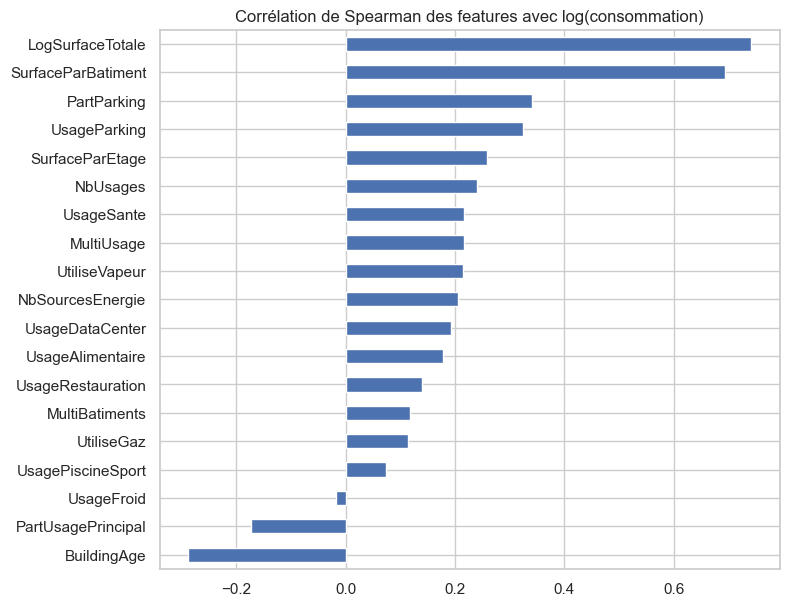

BuildingAge          -0.29
PartUsagePrincipal   -0.17
UsageFroid           -0.02
UsagePiscineSport     0.07
UtiliseGaz            0.11
MultiBatiments        0.12
UsageRestauration     0.14
UsageAlimentaire      0.18
UsageDataCenter       0.19
NbSourcesEnergie      0.21
UtiliseVapeur         0.21
MultiUsage            0.22
UsageSante            0.22
NbUsages              0.24
SurfaceParEtage       0.26
UsageParking          0.32
PartParking           0.34
SurfaceParBatiment    0.69
LogSurfaceTotale      0.74
dtype: float64

In [41]:
features_correlation = numeriques.join(df[["UtiliseGaz", "UtiliseVapeur"]])
corr_cible = (
    features_correlation.corrwith(np.log(df[cible]), method="spearman")
    .sort_values()
)
fig, ax = plt.subplots(figsize=(8, 7))
corr_cible.plot(kind="barh", ax=ax)
ax.set_title("Corrélation de Spearman des features avec log(consommation)")
plt.show()
corr_cible.round(2)

Une barre par feature numérique : sa corrélation avec le log de la consommation, de -1 à 1. Une barre longue vers la droite
indique que la consommation augmente avec la feature ; une barre vers la gauche qu'elle diminue ; une barre courte, qu'il y a peu de lien.

Ce premier aperçu ne remplace pas l'entraînement d'un modèle :
- `LogSurfaceTotale` (0,74) reste de loin la plus liée à la consommation ; `SurfaceParBatiment` (0,69) lui est très proche → redondance probable.
- `BuildingAge` est **négativement** liée (-0,29) : les bâtiments récents sont en moyenne plus grands.
- Les indicateurs d'usages et de sources d'énergie ont des corrélations faibles (0,1 à 0,3) **prises isolément** : leur effet joue
  **à surface égale** (un restaurant consomme plus qu'un entrepôt de même taille), ce qu'une corrélation seule ne montre pas.

La sélection finale (suppression des features redondantes) est faite dans la partie suivante.

| Catégorie | Features créées | Colonnes sources | Fuite ? |
|---|---|---|---|
| Temporalité | `BuildingAge`, `PeriodeConstruction` | `YearBuilt` | Non |
| Structure | `LogSurfaceTotale`, `PartParking`, `SurfaceParEtage`, `SurfaceParBatiment`, `MultiBatiments` | surfaces, étages, nombre de bâtiments | Non |
| Usages | `NbUsages`, `MultiUsage`, `PartUsagePrincipal`, `Usage*` (7 binaires), `FamilleUsage` | liste et surface des usages, type principal | Non |
| Sources d'énergie | `UtiliseGaz`, `UtiliseVapeur` (notebook 01), `NbSourcesEnergie` | présence de gaz / vapeur, **jamais la quantité** | Non |
| Localisation | `ZoneVille` | `Neighborhood` | Non |

### Préparation des features pour la modélisation

#### 1. Suppression des colonnes devenues inutiles

Les colonnes brutes qui ont servi à construire les features sont retirées : leur information est désormais portée par les nouvelles features,
sous une forme plus exploitable par un modèle.

| Colonne retirée | Remplacée par |
|---|---|
| `YearBuilt` | `BuildingAge` |
| `PropertyGFATotal`, `PropertyGFABuilding(s)`, `PropertyGFAParking` | `LogSurfaceTotale`, `PartParking`, `SurfaceParEtage` |
| `NumberofBuildings` | `MultiBatiments` |
| `ListOfAllPropertyUseTypes` | `NbUsages` et les 7 indicateurs d'usages énergivores |
| `LargestPropertyUseTypeGFA` | `PartUsagePrincipal` |
| `PrimaryPropertyType` (20 modalités) | `FamilleUsage` (9 familles) |
| `Neighborhood` (13 quartiers) | `ZoneVille` (3 zones) |

In [42]:
colonnes_brutes = [
    "YearBuilt", "PropertyGFATotal", "PropertyGFABuilding(s)", "PropertyGFAParking", "NumberofBuildings",
    "ListOfAllPropertyUseTypes", "LargestPropertyUseTypeGFA", "PrimaryPropertyType", "Neighborhood",
]
data = df.drop(columns=colonnes_brutes)
print(data.shape)
data.columns.tolist()

(1454, 24)


['NumberofFloors',
 'UtiliseGaz',
 'UtiliseVapeur',
 'SiteEnergyUse(kBtu)',
 'BuildingAge',
 'PeriodeConstruction',
 'LogSurfaceTotale',
 'PartParking',
 'SurfaceParEtage',
 'SurfaceParBatiment',
 'MultiBatiments',
 'NbUsages',
 'MultiUsage',
 'PartUsagePrincipal',
 'UsageRestauration',
 'UsageAlimentaire',
 'UsageSante',
 'UsageDataCenter',
 'UsagePiscineSport',
 'UsageFroid',
 'UsageParking',
 'FamilleUsage',
 'NbSourcesEnergie',
 'ZoneVille']

Il reste **24 colonnes** : les features créées, les colonnes déjà exploitables telles quelles (`NumberofFloors`, `UtiliseGaz`, `UtiliseVapeur`)
et la cible. Les redondances entre features sont traitées plus bas, à l'aide de la matrice de corrélation.

#### 2. Distribution de la cible et valeurs extrêmes

On compare plusieurs méthodes classiques de détection des valeurs extrêmes sur la consommation, en comptant combien de bâtiments
chacune supprimerait :
- **IQR** : valeur extrême si elle s'éloigne de plus de 1,5 fois l'écart interquartile (Q3 - Q1) au-delà des quartiles ;
- **z-score** : valeur extrême si elle s'éloigne de plus de 3 écarts-types de la moyenne ;
- **quantiles** : on retire les 0,5 % de bâtiments les plus bas et les 0,5 % les plus hauts.

In [43]:
y_brut = data[cible]
q1, q3 = y_brut.quantile([0.25, 0.75])
iqr = q3 - q1
methodes = {
    "IQR": (y_brut < q1 - 1.5 * iqr) | (y_brut > q3 + 1.5 * iqr),
    "z-score > 3": ((y_brut - y_brut.mean()) / y_brut.std()).abs() > 3,
    "Quantiles 0,5 % / 99,5 %": (y_brut < y_brut.quantile(0.005)) | (y_brut > y_brut.quantile(0.995)),
}
pd.DataFrame({
    "Bâtiments retirés": {nom: masque.sum() for nom, masque in methodes.items()},
    "% du jeu": {nom: round(masque.mean() * 100, 1) for nom, masque in methodes.items()},
})

,Bâtiments retirés,% du jeu
IQR,158,10.9
z-score > 3,20,1.4
"Quantiles 0,5 % / 99,5 %",16,1.1


- La méthode **IQR** supprimerait **158 bâtiments (11 %)** : comme la consommation est très asymétrique, elle considère comme extrêmes tous les
  grands bâtiments, qui sont pourtant de vrais bâtiments et nombreux. C'est beaucoup trop.
- Le **z-score** en supprimerait 20 (1,4 %), mais il s'appuie sur la moyenne et l'écart-type, eux-mêmes tirés vers le haut par les géants.
- Les **seuils de quantiles** en suppriment 16 (1,1 %), à parts égales en bas et en haut de la distribution.

On retient les **quantiles 0,5 % / 99,5 %** : ils retirent les cas les plus extrêmes sans réduire significativement le jeu de données.

In [44]:
seuil_bas, seuil_haut = y_brut.quantile([0.005, 0.995])
extremes = (y_brut < seuil_bas) | (y_brut > seuil_haut)
print(f"Seuils : {seuil_bas:,.0f} kBtu / {seuil_haut:,.0f} kBtu")
df.loc[extremes[extremes].index, ["PrimaryPropertyType", "PropertyGFATotal", cible]].sort_values(cible)

Seuils : 116,739 kBtu / 92,320,720 kBtu


,PrimaryPropertyType,PropertyGFATotal,SiteEnergyUse(kBtu)
886,Self-Storage Facility,39952,5.713320e+04
1346,Warehouse,23040,7.971180e+04
646,Warehouse,33300,9.055870e+04
885,Self-Storage Facility,30989,9.769040e+04
1125,Warehouse,24617,1.069180e+05
1123,Self-Storage Facility,24248,1.119697e+05
943,Warehouse,21936,1.131300e+05
857,Warehouse,20140,1.164866e+05
480,Large Office,1952220,9.293764e+07
924,Medical Office,591981,1.026737e+08


Les 16 bâtiments retirés, du plus petit au plus gros consommateur :
- **en bas**, 8 entrepôts et garde-meubles de 20 000 à 40 000 pieds² qui consomment presque rien (chauffés au minimum, peu éclairés) ;
- **en haut**, 8 sites géants (hôpitaux, université, très grands bureaux) qui consomment entre 90 et 290 millions de kBtu.

Ces bâtiments sont réels, mais trop peu nombreux et trop différents des autres pour que le modèle apprenne leur comportement :
ils fausseraient l'apprentissage sur la grande majorité des bâtiments.

In [45]:
avant = len(data)
data = data[~extremes]
print(f"Valeurs extrêmes : {avant} → {len(data)} ({avant - len(data)} retirés)")

manquants = data["PartUsagePrincipal"].isna()
data = data[~manquants]
print(f"Usage principal non renseigné : {len(data) + manquants.sum()} → {len(data)} ({manquants.sum()} retirés)")

Valeurs extrêmes : 1454 → 1438 (16 retirés)
Usage principal non renseigné : 1438 → 1434 (4 retirés)


On retire aussi les **4 bâtiments** dont l'usage principal n'est pas renseigné (`PartUsagePrincipal` manquante) : les remplacer
par une valeur inventée apporterait peu pour seulement 0,3 % des données.

Au total, il reste **1 434 bâtiments** sur 1 454, soit **98,6 %** du jeu : la taille du dataset est préservée.

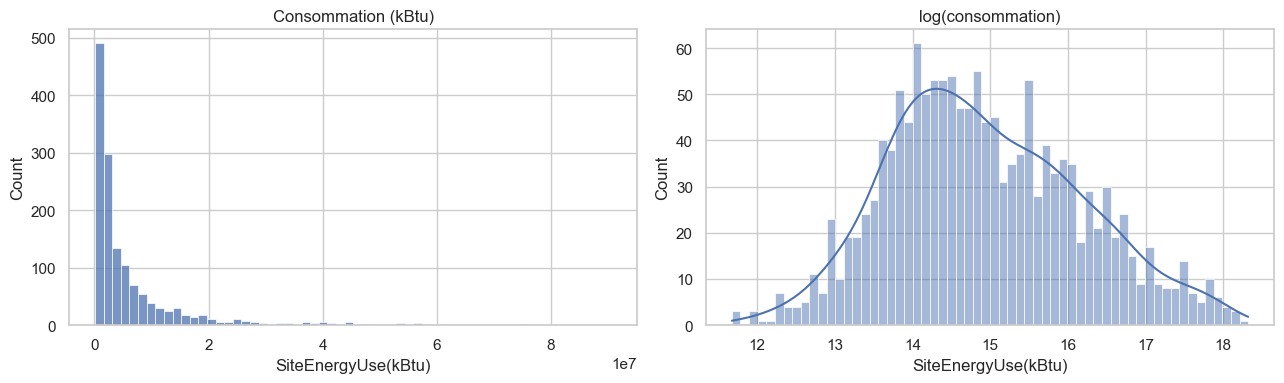

Asymétrie brute : 3.4 — après log : 0.29


In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data[cible], bins=60, ax=axes[0])
axes[0].set_title("Consommation (kBtu)")
sns.histplot(np.log(data[cible]), bins=60, kde=True, ax=axes[1])
axes[1].set_title("log(consommation)")
plt.tight_layout()
plt.show()
print(f"Asymétrie brute : {data[cible].skew():.1f} — après log : {np.log(data[cible]).skew():.2f}")

Après suppression des valeurs extrêmes, la consommation reste très asymétrique (asymétrie de 3,4) : la plupart des bâtiments
consomment quelques millions de kBtu, quelques-uns plusieurs dizaines de millions. En **log**, la distribution devient une cloche
régulière (asymétrie de 0,29). C'est le log de la consommation que le modèle apprendra à prédire.

#### 3. Features redondantes

Deux features très corrélées apportent la même information : en garder une seule simplifie le modèle et rend son interprétation plus fiable
(un modèle linéaire répartit l'effet de façon instable entre deux features redondantes).

La matrice de corrélation ne s'applique qu'aux features **numériques** (y compris les binaires 0 / 1) : `FamilleUsage`, `ZoneVille`
et `PeriodeConstruction` sont des catégories, elles sont étudiées avec des boxplots dans la partie suivante.

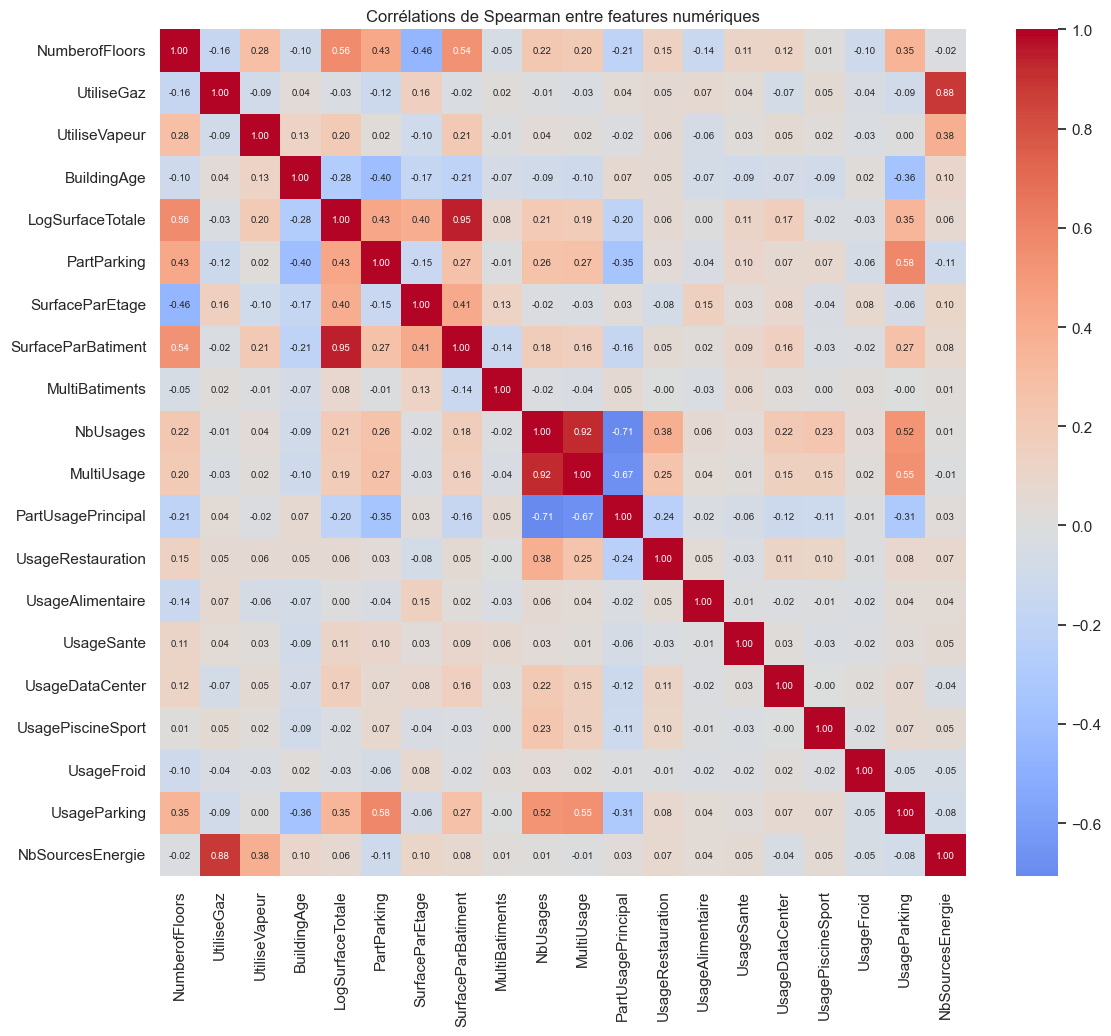

,,corrélation
LogSurfaceTotale,SurfaceParBatiment,0.95
NbUsages,MultiUsage,0.92
UtiliseGaz,NbSourcesEnergie,0.88
NbUsages,PartUsagePrincipal,-0.71


In [47]:
numeriques = data.drop(columns=cible).select_dtypes("number")
corr = numeriques.corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, ax=ax)
ax.set_title("Corrélations de Spearman entre features numériques")
plt.show()

paires = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
paires[paires.abs() > 0.7].sort_values(ascending=False).round(2).to_frame("corrélation")

Chaque case donne la corrélation entre deux features (rouge = forte et positive, bleu = négative). Le tableau liste les paires
dont la corrélation dépasse 0,7 en valeur absolue :

| Paire | Corrélation | Décision |
|---|---|---|
| `LogSurfaceTotale` / `SurfaceParBatiment` | 0,95 | On garde `LogSurfaceTotale`, plus liée à la consommation (0,74 contre 0,69). Presque toutes les propriétés n'ayant qu'un bâtiment, les deux disent la même chose |
| `NbUsages` / `MultiUsage` | 0,92 | On garde `NbUsages` : `MultiUsage` (1 si plus d'un usage) s'en déduit directement |
| `UtiliseGaz` / `NbSourcesEnergie` | 0,88 | On garde `UtiliseGaz` et `UtiliseVapeur`, plus précises : elles disent **quelle** source, pas seulement combien |
| `NbUsages` / `PartUsagePrincipal` | -0,71 | On garde les deux : la corrélation reste modérée, et la part de surface apporte une nuance que le simple comptage n'a pas |

#### 4. Lien entre les features et la cible

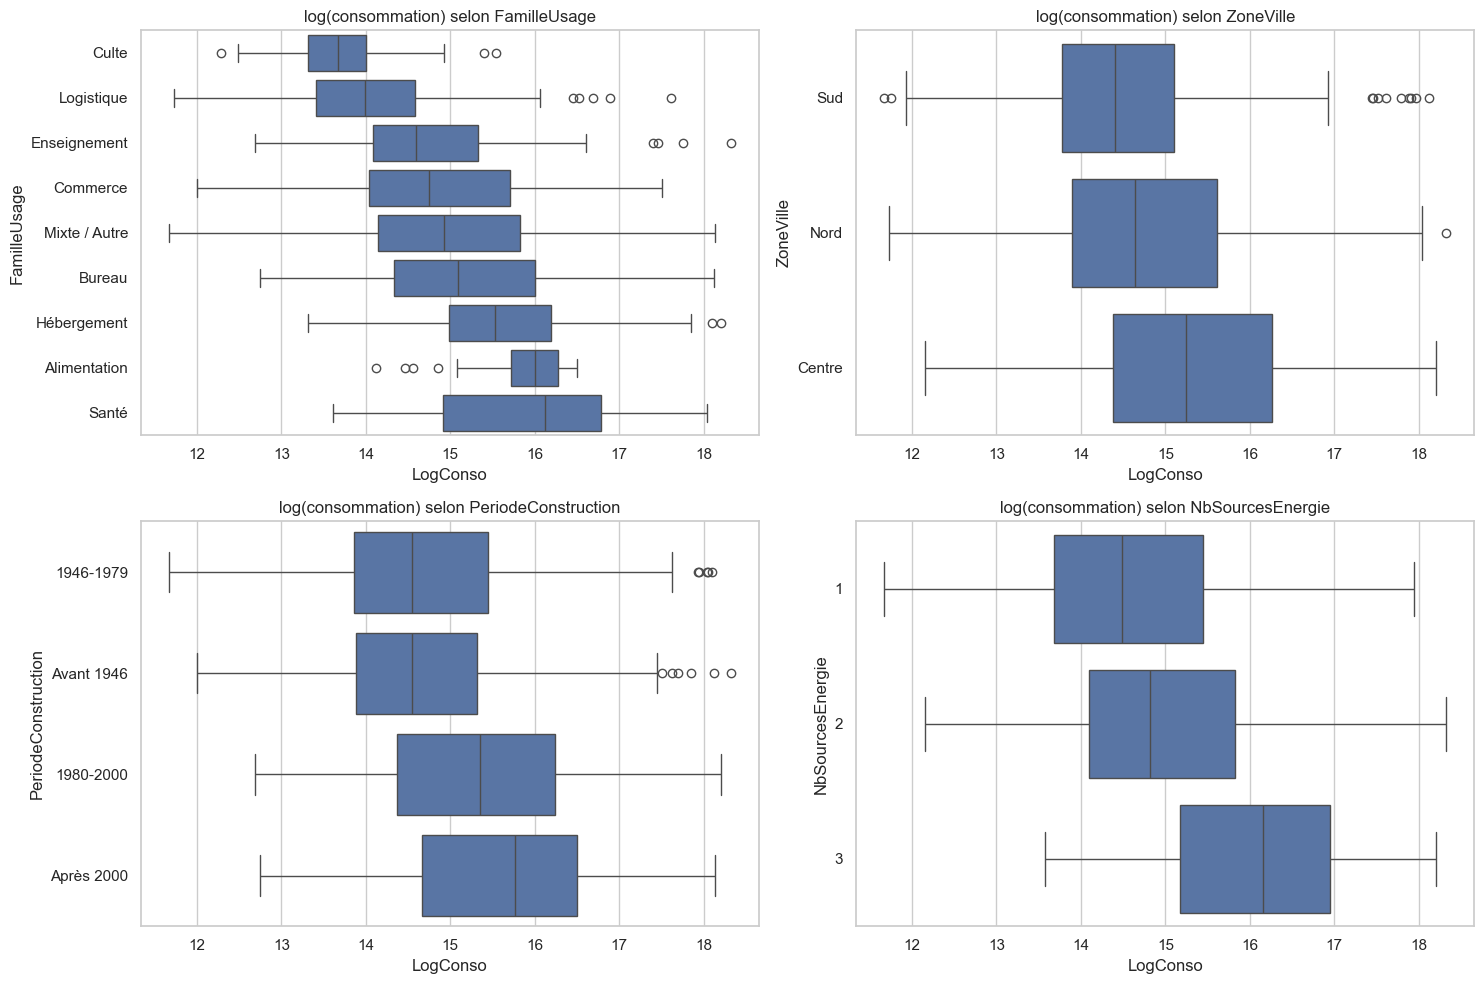

In [48]:
data_graph = data.assign(LogConso=np.log(data[cible]))
categories = ["FamilleUsage", "ZoneVille", "PeriodeConstruction", "NbSourcesEnergie"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for col, ax in zip(categories, axes.flat):
    ordre = data_graph.groupby(col, observed=True)["LogConso"].median().sort_values().index
    sns.boxplot(data=data_graph, x="LogConso", y=col, order=ordre, orient="h", ax=ax)
    ax.set_title(f"log(consommation) selon {col}")
plt.tight_layout()
plt.show()

Chaque boîte montre la répartition du log de la consommation pour une catégorie (trait central = médiane, boîte = moitié centrale
des bâtiments). Les catégories sont triées de la plus faible à la plus forte médiane.

- **Famille d'usage** : c'est la catégorie qui sépare le mieux les bâtiments. Médiane d'environ 10 millions de kBtu pour la **santé** et 9 millions
  pour l'**alimentation**, contre 1,2 million pour la **logistique** et moins d'1 million pour le **culte**.
- **Zone** : le **Centre** consomme plus (médiane 4,2 millions) que le Nord (2,3) et le Sud (1,8). Ramenée à la surface, la différence
  est faible : l'écart vient surtout de la taille et du type des bâtiments du centre (tours de bureaux, hôtels).
- **Période de construction** : les bâtiments récents consomment plus (médiane 7 millions après 2000, contre 2 millions avant 1980),
  mais ils sont surtout plus grands : ramenée à la surface, la consommation varie peu d'une période à l'autre.
- **Nombre de sources d'énergie** : les 59 bâtiments qui combinent électricité, gaz et vapeur consomment nettement plus
  (médiane d'environ 10 millions) que ceux à une seule source (2 millions). L'écart persiste ramené à la surface.

In [49]:
binaires = ["UsageDataCenter", "UsageSante", "UsageRestauration", "UsageAlimentaire", "UsagePiscineSport",
            "UsageFroid", "UsageParking", "UtiliseGaz", "UtiliseVapeur", "MultiUsage", "MultiBatiments"]
tendances = pd.DataFrame({
    "Médiane sans (M kBtu)": [data.loc[data[b] == 0, cible].median() / 1e6 for b in binaires],
    "Médiane avec (M kBtu)": [data.loc[data[b] == 1, cible].median() / 1e6 for b in binaires],
    "Nb bâtiments avec": [int(data[b].sum()) for b in binaires],
}, index=binaires).round(2)
tendances["Rapport"] = (tendances["Médiane avec (M kBtu)"] / tendances["Médiane sans (M kBtu)"]).round(1)
tendances.sort_values("Rapport", ascending=False)

,Médiane sans (M kBtu),Médiane avec (M kBtu),Nb bâtiments avec,Rapport
UsageSante,2.58,24.40,35,9.5
UsageDataCenter,2.56,14.16,42,5.5
UsageAlimentaire,2.52,8.93,61,3.5
UtiliseVapeur,2.47,8.58,103,3.5
UsageParking,2.07,6.21,386,3.0
MultiBatiments,2.60,5.66,35,2.2
UsageRestauration,2.50,5.09,125,2.0
UsagePiscineSport,2.63,5.39,38,2.0
MultiUsage,1.97,3.57,793,1.8
UtiliseGaz,2.30,2.77,1024,1.2


Pour chaque feature binaire : consommation médiane des bâtiments qui n'ont pas la caractéristique (sans) et de ceux qui l'ont (avec),
puis le rapport entre les deux.
- Les bâtiments avec un usage de **santé** consomment environ **9 fois plus** que les autres, ceux avec un **data center** 5,5 fois plus,
  ceux avec un commerce **alimentaire** ou raccordés à la **vapeur** 3,5 fois plus.
- Être équipé au **gaz** ne change presque rien (rapport de 1,2) : c'est le cas de 71 % des bâtiments, de toutes tailles.
- Les **entrepôts frigorifiques** consomment moins que la médiane (rapport de 0,5) : ce sont surtout des entrepôts, peu consommateurs
  en dehors du froid. Avec 16 bâtiments seulement, cette tendance reste fragile.

Ces écarts mélangent l'effet de l'usage et celui de la taille (un hôpital est aussi un grand bâtiment) : c'est le modèle qui les séparera.

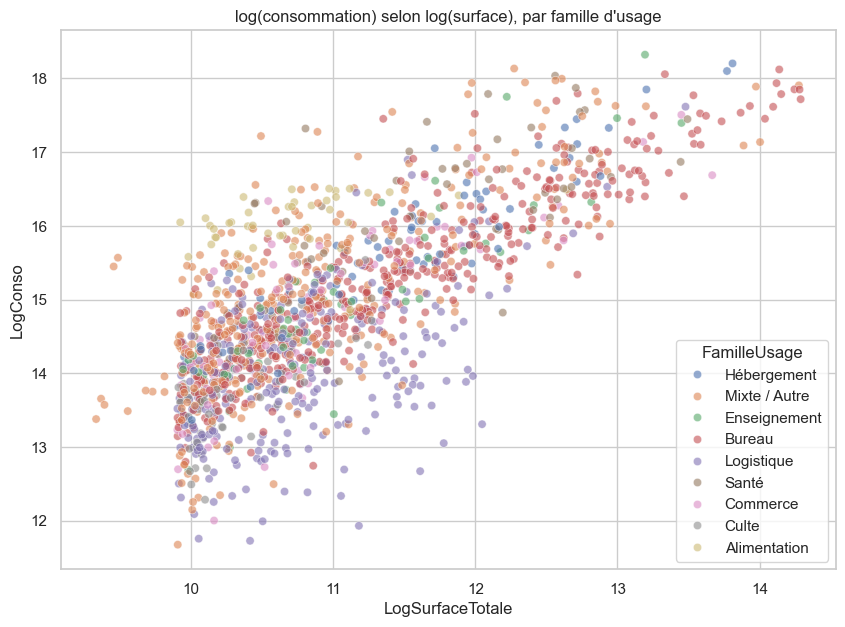

In [50]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=data_graph, x="LogSurfaceTotale", y="LogConso", hue="FamilleUsage", alpha=0.6, ax=ax)
ax.set_title("log(consommation) selon log(surface), par famille d'usage")
plt.show()

Chaque point est un bâtiment, coloré selon sa famille d'usage. Les points forment une bande qui monte : la surface reste le premier
facteur de consommation. À surface égale, les familles se superposent en couches : l'**alimentation** et la **santé** sont au-dessus de la bande,
la **logistique** et le **culte** en dessous. La famille d'usage explique donc une partie de l'écart que la surface seule ne capte pas.

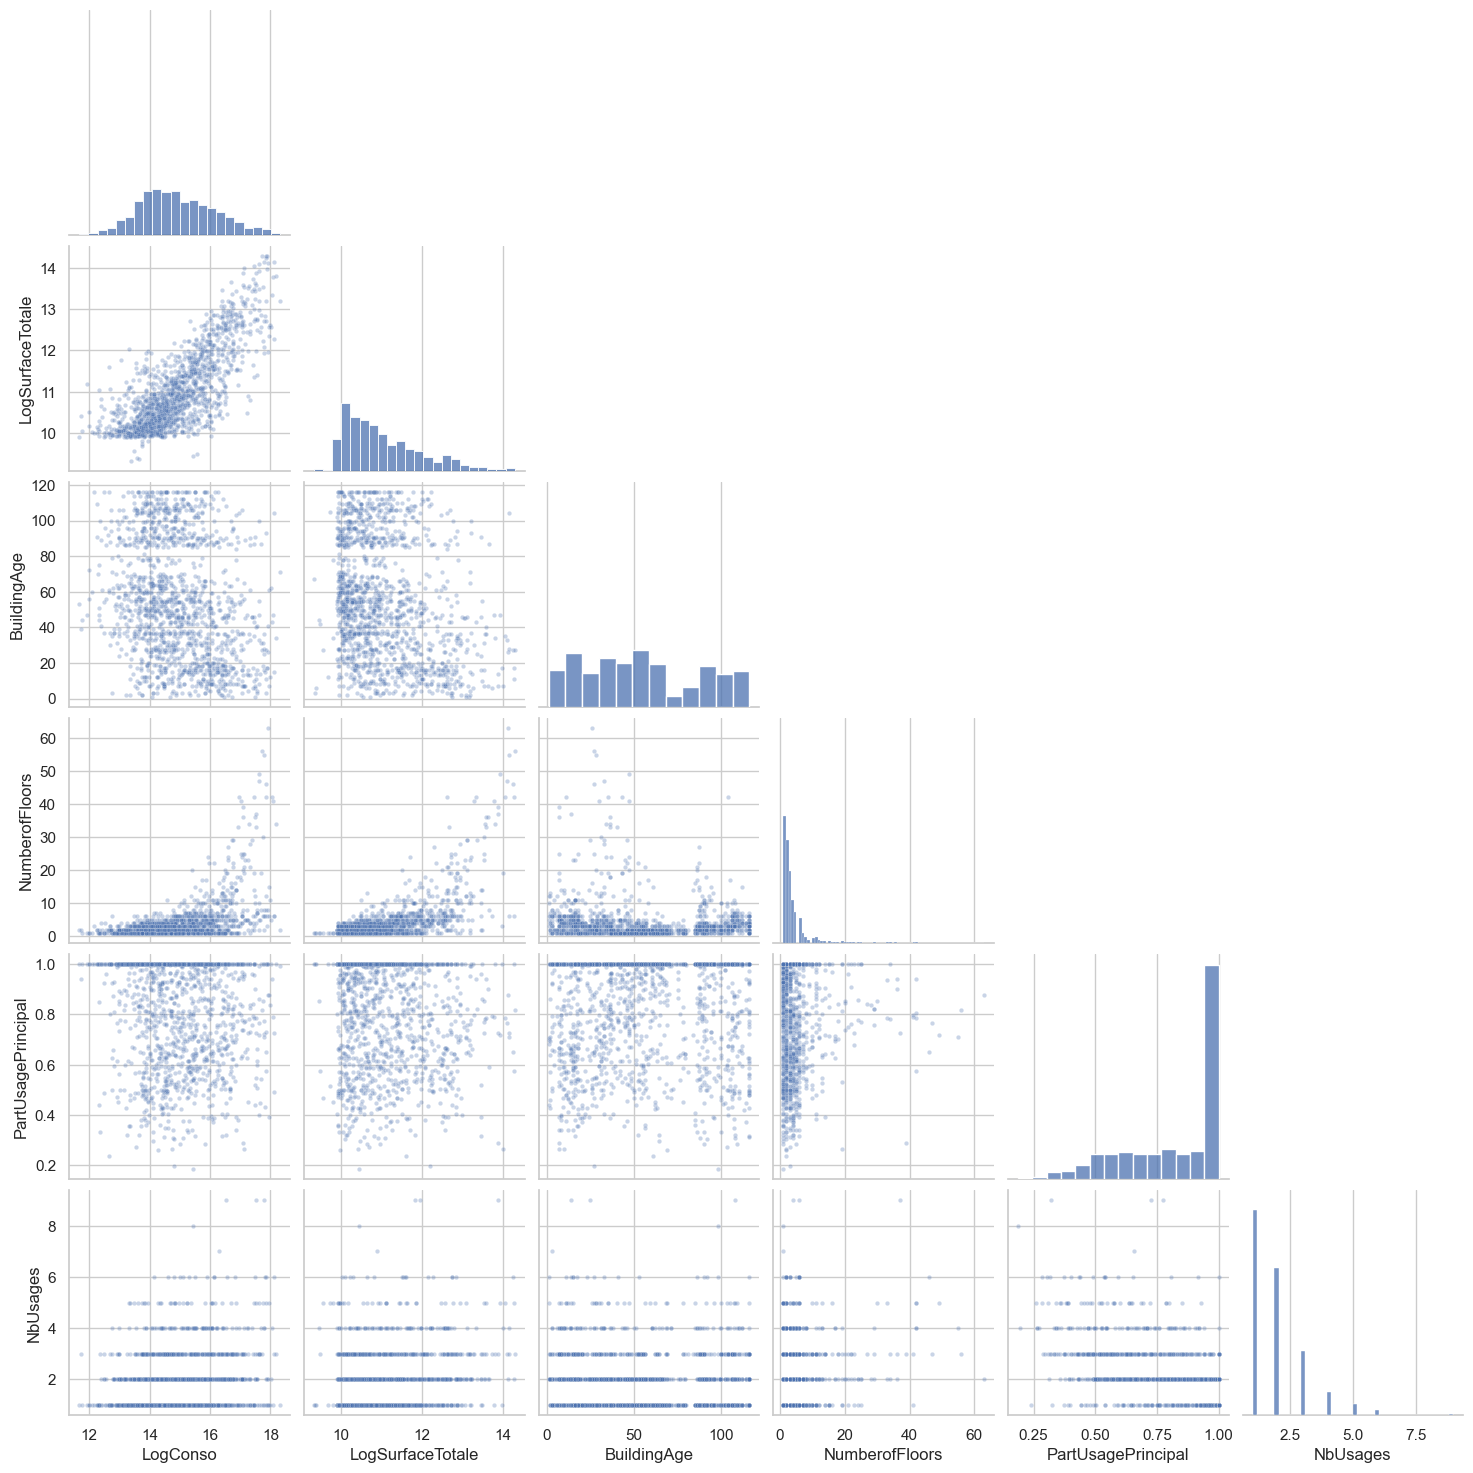

In [51]:
sns.pairplot(data_graph[["LogConso", "LogSurfaceTotale", "BuildingAge", "NumberofFloors", "PartUsagePrincipal", "NbUsages"]],
             plot_kws={"alpha": 0.3, "s": 10}, corner=True)
plt.show()

Chaque case croise deux features (nuage de points), la diagonale montre la distribution de chacune. La première colonne
montre le lien avec le log de la consommation :
- `LogSurfaceTotale` : lien fort et en ligne droite ;
- `NumberofFloors` : lien positif mais moins net (beaucoup de bâtiments bas de toutes tailles) ;
- `BuildingAge`, `PartUsagePrincipal`, `NbUsages` : nuages diffus, sans tendance nette prises isolément.

#### 5. Sélection finale des features

In [52]:
features_retirees = ["SurfaceParBatiment", "MultiUsage", "NbSourcesEnergie", "PeriodeConstruction"]
data["LogSurfaceParEtage"] = np.log(data["SurfaceParEtage"])
data = data.drop(columns=features_retirees + ["SurfaceParEtage"])

features_continues = ["LogSurfaceTotale", "LogSurfaceParEtage", "NumberofFloors", "BuildingAge",
                      "PartParking", "PartUsagePrincipal", "NbUsages"]
features_binaires = ["MultiBatiments", "UtiliseGaz", "UtiliseVapeur", *usages_intensifs]
features_categorielles = ["FamilleUsage", "ZoneVille"]

assert set(features_continues + features_binaires + features_categorielles + [cible]) == set(data.columns)
print(f"{len(features_continues)} continues :", features_continues)
print(f"{len(features_binaires)} binaires :", features_binaires)
print(f"{len(features_categorielles)} catégorielles :", features_categorielles)

7 continues : ['LogSurfaceTotale', 'LogSurfaceParEtage', 'NumberofFloors', 'BuildingAge', 'PartParking', 'PartUsagePrincipal', 'NbUsages']
10 binaires : ['MultiBatiments', 'UtiliseGaz', 'UtiliseVapeur', 'UsageRestauration', 'UsageAlimentaire', 'UsageSante', 'UsageDataCenter', 'UsagePiscineSport', 'UsageFroid', 'UsageParking']
2 catégorielles : ['FamilleUsage', 'ZoneVille']


Les features redondantes sont retirées (`SurfaceParBatiment`, `MultiUsage`, `NbSourcesEnergie`), ainsi que `PeriodeConstruction` :
l'âge est déjà donné par `BuildingAge`, et les boxplots ont montré que la période n'a pas d'effet propre une fois la taille prise en compte.

`SurfaceParEtage` est remplacée par son log (`LogSurfaceParEtage`) : comme la surface totale, elle va de quelques milliers à plus d'un million
de pieds², et le log resserre ces valeurs.

On obtient **19 features**, rangées en trois groupes qui seront traités différemment à l'encodage :
- **7 continues** : surfaces, étages, âge, parts, nombre d'usages ;
- **10 binaires** (0 / 1) : plusieurs bâtiments, sources d'énergie, usages énergivores ;
- **2 catégorielles** : famille d'usage et zone.

La ligne `assert` vérifie qu'aucune colonne n'a été oubliée ou comptée deux fois.

#### 6. Séparation des features (X) et de la cible (y)

La cible est passée au **log** : sa distribution devient symétrique, et le modèle n'est plus dominé par les quelques très gros bâtiments.
Les prédictions seront ramenées en kBtu avec l'exponentielle (`np.exp`).

In [53]:
X = data[features_continues + features_binaires + features_categorielles]
y = np.log(data[cible])
print("X :", X.shape, "| y :", y.shape)
X.head()

X : (1434, 19) | y : (1434,)


,LogSurfaceTotale,LogSurfaceParEtage,NumberofFloors,BuildingAge,PartParking,PartUsagePrincipal,NbUsages,MultiBatiments,UtiliseGaz,UtiliseVapeur,UsageRestauration,UsageAlimentaire,UsageSante,UsageDataCenter,UsagePiscineSport,UsageFroid,UsageParking,FamilleUsage,ZoneVille
0,11.390012,8.905105,12,89,0.000000,1.000000,1,0,1,1,0,0,0,0,0,0,0,Hébergement,Centre
1,11.547964,8.992885,11,20,0.145453,0.809918,3,0,1,0,1,0,0,0,0,0,1,Hébergement,Centre
2,13.770628,9.826701,41,47,0.205748,0.791220,1,0,1,1,0,0,0,0,0,0,0,Hébergement,Centre
3,11.023861,8.721276,10,90,0.000000,1.000000,1,0,1,1,0,0,0,0,0,0,0,Hébergement,Centre
4,12.075850,8.749891,18,36,0.353115,0.703070,3,0,1,0,0,0,0,0,1,0,1,Hébergement,Centre


`X` contient les **19 features** des **1 434 bâtiments**, `y` le log de leur consommation. Les deux ont bien le même nombre de lignes.

#### 7. Encodage des features catégorielles

Un modèle ne manipule que des nombres : les catégories doivent être encodées.

| Encodeur | Principe | Quand l'utiliser |
|---|---|---|
| `LabelEncoder` | Remplace chaque catégorie par un entier (0, 1, 2…) | Pour une **cible** catégorielle (classification). Sur une feature, il inventerait un ordre qui n'existe pas : `Bureau` = 1, `Culte` = 3 laisserait croire que le culte vaut « trois fois » le bureau |
| `OneHotEncoder` | Crée une colonne 0 / 1 par catégorie | Pour une feature **sans ordre** et avec **peu de modalités** |

`FamilleUsage` (9 familles) et `ZoneVille` (3 zones) n'ont pas d'ordre et peu de modalités : on utilise le `OneHotEncoder`.
C'est pour éviter d'en créer un trop grand nombre de colonnes que `PrimaryPropertyType` (20 types) et `Neighborhood` (13 quartiers) ont été
compressés en familles et en zones lors du feature engineering. Par sécurité, `max_categories=10` regroupe dans une colonne « autre »
les éventuelles modalités au-delà de 10.

Les features continues ont des ordres de grandeur très différents (âge en dizaines d'années, parts entre 0 et 1, nombre d'étages…) :
elles sont mises à l'échelle avec un `StandardScaler` (moyenne 0, écart-type 1) pour les modèles qui y sont sensibles (linéaires, SVM).
Les features binaires valent déjà 0 ou 1 : elles sont laissées telles quelles (`passthrough`), ce qui les garde lisibles.

L'encodeur et le scaler sont regroupés dans un `ColumnTransformer`. Ils ne sont **pas ajustés ici** sur tout le jeu de données :
ils le seront sur le jeu d'entraînement seulement, dans chaque modèle, pour éviter toute fuite d'information entre entraînement et test.

In [54]:
preprocesseur = ColumnTransformer([
    ("continues", StandardScaler(), features_continues),
    ("binaires", "passthrough", features_binaires),
    ("categorielles", OneHotEncoder(handle_unknown="ignore", max_categories=10), features_categorielles),
])

# Aperçu du résultat de l'encodage (le préprocesseur sera réajusté sur le jeu d'entraînement dans chaque modèle)
apercu = preprocesseur.fit(X).transform(X)
colonnes_encodees = preprocesseur.get_feature_names_out()
print("Matrice encodée :", apercu.shape)
pd.DataFrame(apercu, columns=colonnes_encodees, index=X.index).head().round(2)

Matrice encodée : (1434, 29)


,continues__LogSurfaceTotale,continues__LogSurfaceParEtage,continues__NumberofFloors,continues__BuildingAge,continues__PartParking,continues__PartUsagePrincipal,continues__NbUsages,binaires__MultiBatiments,binaires__UtiliseGaz,binaires__UtiliseVapeur,binaires__UsageRestauration,binaires__UsageAlimentaire,binaires__UsageSante,binaires__UsageDataCenter,binaires__UsagePiscineSport,binaires__UsageFroid,binaires__UsageParking,categorielles__FamilleUsage_Alimentation,categorielles__FamilleUsage_Bureau,categorielles__FamilleUsage_Commerce,categorielles__FamilleUsage_Culte,categorielles__FamilleUsage_Enseignement,categorielles__FamilleUsage_Hébergement,categorielles__FamilleUsage_Logistique,categorielles__FamilleUsage_Mixte / Autre,categorielles__FamilleUsage_Santé,categorielles__ZoneVille_Centre,categorielles__ZoneVille_Nord,categorielles__ZoneVille_Sud
0,0.38,-1.39,1.27,1.05,-0.47,0.87,-0.81,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.55,-1.27,1.11,-1.05,0.52,-0.06,0.92,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2.92,-0.16,6.01,-0.23,0.92,-0.15,-0.81,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.01,-1.63,0.94,1.08,-0.47,0.87,-0.81,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.11,-1.60,2.25,-0.56,1.92,-0.58,0.92,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


Après encodage, on obtient **29 colonnes** : les 7 features continues mises à l'échelle (centrées autour de 0), les 10 binaires inchangées,
et 12 colonnes 0 / 1 créées par le `OneHotEncoder` (9 familles + 3 zones). Sur chaque ligne, une seule colonne de famille et une seule
colonne de zone valent 1 : par exemple, les 5 premiers bâtiments sont des hôtels du centre, donc `FamilleUsage_Hébergement` = 1 et `ZoneVille_Centre` = 1.

#### Synthèse de la préparation

| Étape | Choix | Justification |
|---|---|---|
| Colonnes brutes | Retirées | Leur information est portée par les features créées |
| Valeurs extrêmes | 16 bâtiments retirés (quantiles 0,5 % / 99,5 %) | L'IQR en retirait 11 % ; les quantiles retirent seulement les cas les plus atypiques |
| Valeurs manquantes | 4 bâtiments retirés | Usage principal non renseigné, 0,3 % des données |
| Cible | Passage au log | Distribution symétrique, modèle non dominé par les plus gros bâtiments |
| Redondances | 3 features retirées | Corrélations de 0,88 à 0,95 avec une autre feature |
| Encodage | `OneHotEncoder` sur les 2 catégorielles | Catégories sans ordre et peu nombreuses |
| Mise à l'échelle | `StandardScaler` sur les 7 continues | Ordres de grandeur très différents |

Le jeu final compte **1 434 bâtiments** (98,6 % du jeu nettoyé) et **19 features**, sans fuite de données.

### Comparaison de différents modèles supervisés

In [55]:
# CODE COMPARAISON DES MODELES

### Optimisation et interprétation du modèle

In [56]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE